# DL_02: Corr2Cause Causal Entailment with Fine-Tuned DistilBERT
**Causal NLP Reasoning — Phase 2: Deep Learning**

---

## 1. Purpose and Scope
This notebook implements fine-tuning of **DistilBERT** (`distilbert-base-uncased`) for binary causal sequence entailment on the **Corr2Cause** benchmark.

Key requirements:
- Frame causal discovery deduction as sequence classification: `[CLS] Premise [SEP] Hypothesis [SEP]`.
- Train on canonical training split (205,734 pairs) with checkpoint selection strictly on the validation split (1,076 pairs).
- Never evaluate or peek at the held-out test split (1,162 pairs) during hyperparameter tuning.
- Optimize using AdamW, linear learning rate warmup, and mixed precision (FP16 only when CUDA is available).
- Use conservative default batch size (16) and gradient accumulation (1).
- Configure modern `eval_strategy='epoch'` (conforming to modern Transformers specifications).
- Compute final evaluation metrics on held-out test split: Accuracy, Macro-F1, Precision, and Recall.
- Export test prediction logits and labels for comparative evaluation in `DL_05`.

## 2. Experimental Methodology & Theoretical Background

### Abstract Causal Discovery as Deductive Entailment
Corr2Cause tests whether language models can determine whether a causal conjecture is mathematically entailed by observed conditional independencies:
- Given variables $V = \{X_1, X_2, \dots, X_n\}$ and statistical statements (e.g. $X_1 \perp X_2 \mid X_3$), determine if $X_i \to X_j$ is uniquely implied.
- The objective is binary sequence classification: Cross-entropy loss over the `[CLS]` pooled classification representation.

### Hardware & Compute Efficiency
- DistilBERT features 66M parameters, trains rapidly, and fits comfortably within free Kaggle (T4 x 2) and Google Colab (T4) memory bounds.
- Canonical split counts: Train = 205,734 | Validation = 1,076 | Test = 1,162.

## 3. Expected Inputs

| Split | Path | Exact Row Count | Columns |
| :--- | :--- | :--- | :--- |
| **Train** | `data/raw/train.csv` (or `data/processed/dl_corr2cause_train.csv`) | 205,734 | `input, label, num_variables, template` |
| **Validation** | `data/raw/validation.csv` (or `data/processed/dl_corr2cause_val.csv`) | 1,076 | `input, label, num_variables, template` |
| **Test** | `data/raw/test.csv` (or `data/processed/dl_corr2cause_test.csv`) | 1,162 | `input, label, num_variables, template` |

## 4. Technical Responsibilities & Implementation Requirements

1. **Portable Root & Hardware Detection**: Check GPU availability (CUDA / MPS / CPU) and locate project root.
2. **Configurable Hyperparameters**: Conservative defaults: Batch size (16), gradient accumulation (1), learning rate ($2 \times 10^{-5}$), weight decay (0.01), epochs (3), FP16 (CUDA only), `eval_strategy='epoch'`.
3. **Tokenization**: Tokenize premise-hypothesis pairs with `distilbert-base-uncased`.
4. **Model Architecture**: Initialize `AutoModelForSequenceClassification` with 2 labels.
5. **Training Execution**: Run training with validation evaluation at each epoch.
6. **Validation Selection**: Select best model weights strictly using validation Macro-F1.
7. **Test Set Evaluation & Export**: Run final test evaluation once and export predictions to `data/processed/`.

In [1]:
# Section 1: Environment Setup & Portable Imports
import os
import sys
import json
import warnings
import re
from pathlib import Path

# Portability setup across Local repo, Colab, and Kaggle
def find_repo_root():
    curr = Path(os.getcwd()).resolve()
    for p in [curr] + list(curr.parents):
        if (p / 'AML' / 'causal_extractors.py').exists() and (p / 'DL' / 'dl_utils.py').exists():
            return p
        if (p / 'dl_utils.py').exists():
            return p
    if Path('/kaggle/working').exists():
        repo_target = Path('/kaggle/working/causal-nlp-reasoning')
        if (repo_target / 'DL' / 'dl_utils.py').exists():
            return repo_target
        return Path('/kaggle/working')
    return curr

ROOT_DIR = find_repo_root()

# In Kaggle, if repo not found, clone it to access dl_utils and other modules
if Path('/kaggle/working').exists() and not (ROOT_DIR / 'DL' / 'dl_utils.py').exists() and not (ROOT_DIR / 'dl_utils.py').exists():
    import subprocess
    print("Cloning repository on Kaggle...")
    repo_target = Path('/kaggle/working/causal-nlp-reasoning')
    if not repo_target.exists():
        subprocess.run(['git', 'clone', 'https://github.com/alpha-sml/causal-nlp-reasoning.git', str(repo_target)], check=True)
    ROOT_DIR = repo_target

for p in [ROOT_DIR, ROOT_DIR / 'AML', ROOT_DIR / 'DL']:
    p_str = str(p)
    if p_str not in sys.path:
        sys.path.insert(0, p_str)

import dl_utils
print(f'Repository root located at: {ROOT_DIR}')

Repository root located at: /kaggle/working/causal-nlp-reasoning


In [2]:
# Section 2: Configurable Hyperparameters & Hardware Detection
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification, Trainer, DataCollatorWithPadding
from datasets import Dataset
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')

# Model & Training Configuration Constants
MODEL_CHECKPOINT = dl_utils.DISTILBERT_CHECKPOINT
BATCH_SIZE = dl_utils.DEFAULT_DISTILBERT_BATCH_SIZE  # Conservative default: 16
GRAD_ACCUM_STEPS = dl_utils.DEFAULT_DISTILBERT_GRAD_ACCUM  # Default: 1
LEARNING_RATE = 2e-5
NUM_EPOCHS = 3
WEIGHT_DECAY = 0.01
MAX_LENGTH = dl_utils.DEFAULT_CORR2CAUSE_MAX_LENGTH  # 256 tokens
SEED = 42

# FP16 enabled ONLY when CUDA is available (strictly disabled on CPU/MPS for numerical safety)
FP16_ENABLED = torch.cuda.is_available() and not (hasattr(torch.backends, 'mps') and torch.backends.mps.is_available())
EVAL_STRATEGY = 'epoch'  # Modern Transformers argument
SAVE_TOTAL_LIMIT = 2
OUTPUT_DIR = str(ROOT_DIR / 'DL' / 'checkpoints' / 'corr2cause_distilbert')

# Set random seed for full reproducibility across all libraries
dl_utils.set_seed(SEED)

# Hardware and Device Detection
device = dl_utils.get_device()
print(f'PyTorch version: {torch.__version__}')
print(f'CUDA available:  {torch.cuda.is_available()}')
print(f'Active device:   {device}')
print(f'FP16 enabled:    {FP16_ENABLED}')
if torch.cuda.is_available():
    gpu_count = torch.cuda.device_count()
    for i in range(gpu_count):
        props = torch.cuda.get_device_properties(i)
        mem_bytes = getattr(props, "total_memory", getattr(props, "total_mem", 0))
        mem_gb = mem_bytes / (1024**3)
        print(f'  GPU {i}: {torch.cuda.get_device_name(i)} ({mem_gb:.1f} GB)')
else:
    print('Notice: No CUDA GPU available. FP16 disabled.')

print(f'\nTraining Hyperparameters:')
print(f'  Checkpoint:          {MODEL_CHECKPOINT}')
print(f'  Batch size:          {BATCH_SIZE}')
print(f'  Grad accum steps:    {GRAD_ACCUM_STEPS}')
print(f'  Learning rate:       {LEARNING_RATE}')
print(f'  Epochs:              {NUM_EPOCHS}')
print(f'  Weight decay:        {WEIGHT_DECAY}')
print(f'  Max sequence length: {MAX_LENGTH}')
print(f'  Eval strategy:       {EVAL_STRATEGY}')
print(f'  Checkpoint dir:      {OUTPUT_DIR}')

PyTorch version: 2.11.0+cu130
CUDA available:  True
Active device:   cuda
FP16 enabled:    True
  GPU 0: Tesla T4 (14.6 GB)
  GPU 1: Tesla T4 (14.6 GB)

Training Hyperparameters:
  Checkpoint:          distilbert-base-uncased
  Batch size:          16
  Grad accum steps:    1
  Learning rate:       2e-05
  Epochs:              3
  Weight decay:        0.01
  Max sequence length: 256
  Eval strategy:       epoch
  Checkpoint dir:      /kaggle/working/causal-nlp-reasoning/DL/checkpoints/corr2cause_distilbert


In [3]:
# Section 3: Dataset Ingestion & Validation
# Load canonical splits (205,734 train, 1,076 val, 1,162 test)

DATA_DIR = ROOT_DIR / 'data' / 'processed'
RAW_DIR = ROOT_DIR / 'data' / 'raw'

SPLIT_SPECS = {
    'train': ('dl_corr2cause_train.csv', 'train.csv', dl_utils.CORR2CAUSE_SPLIT_COUNTS['train']),
    'validation': ('dl_corr2cause_val.csv', 'validation.csv', dl_utils.CORR2CAUSE_SPLIT_COUNTS['validation']),
    'test': ('dl_corr2cause_test.csv', 'test.csv', dl_utils.CORR2CAUSE_SPLIT_COUNTS['test']),
}

REQUIRED_COLUMNS = ['input', 'label', 'num_variables', 'template']

def load_and_stage_split(split_name, proc_name, raw_name, expected_rows):
    proc_path = DATA_DIR / proc_name
    raw_path = RAW_DIR / raw_name
    
    if proc_path.exists():
        print(f'Loading {split_name} from processed: {proc_path}')
        df = pd.read_csv(proc_path)
    elif raw_path.exists():
        print(f'Loading {split_name} from raw: {raw_path}')
        df = pd.read_csv(raw_path)
    else:
        print(f'Local files missing for {split_name}. Loading canonical from HuggingFace (causal-nlp/corr2cause)...')
        from datasets import load_dataset
        hf_ds = load_dataset('causal-nlp/corr2cause')
        df = hf_ds[split_name].to_pandas()
        
        # Stage both raw and processed versions in line with project standards
        RAW_DIR.mkdir(parents=True, exist_ok=True)
        DATA_DIR.mkdir(parents=True, exist_ok=True)
        df.to_csv(raw_path, index=False)
        df_proc = df.copy()
        df_proc['split'] = split_name
        df_proc.to_csv(proc_path, index=False)
        print(f'  ✓ Staged canonical {raw_path} and {proc_path}')
    
    return df

# Load all splits
train_df = load_and_stage_split('train', *SPLIT_SPECS['train'])
val_df = load_and_stage_split('validation', *SPLIT_SPECS['validation'])
test_df = load_and_stage_split('test', *SPLIT_SPECS['test'])

# Comprehensive Validation Suite
print('\n=== Data Validation Verification ===')
for name, df, expected_rows in [
    ('train', train_df, 205734),
    ('validation', val_df, 1076),
    ('test', test_df, 1162),
]:
    # 1. Schema check via dl_utils
    dl_utils.validate_dataset_schema(df, REQUIRED_COLUMNS, dataset_name=f'Corr2Cause-{name}')
    
    # 2. Exact row count
    assert len(df) == expected_rows, f'{name}: expected {expected_rows} rows, got {len(df)}'
    
    # 3. Binary labels only {0, 1}
    unique_labels = set(df['label'].unique())
    assert unique_labels.issubset({0, 1}), f'{name}: invalid non-binary labels {unique_labels}'
    
    # 4. No missing values in required columns
    for col in REQUIRED_COLUMNS:
        n_miss = df[col].isna().sum()
        assert n_miss == 0, f'{name}: column {col} contains {n_miss} missing values'
        
    label_dist = df['label'].value_counts().to_dict()
    num_vars_dist = df['num_variables'].value_counts().sort_index().to_dict()
    print(f'  ✓ {name:<10}: {len(df):>7,} rows | Labels: {label_dist} | Num Variables: {num_vars_dist}')

print('\nSample Record (Train Index 0):')
print(f'  Input:         {train_df["input"].iloc[0][:160]}...')
print(f'  Label:         {train_df["label"].iloc[0]} (1=entailed, 0=refuted)')
print(f'  Num Variables: {train_df["num_variables"].iloc[0]}')

Local files missing for train. Loading canonical from HuggingFace (causal-nlp/corr2cause)...
  ✓ Staged canonical /kaggle/working/causal-nlp-reasoning/data/raw/train.csv and /kaggle/working/causal-nlp-reasoning/data/processed/dl_corr2cause_train.csv
Local files missing for validation. Loading canonical from HuggingFace (causal-nlp/corr2cause)...
  ✓ Staged canonical /kaggle/working/causal-nlp-reasoning/data/raw/validation.csv and /kaggle/working/causal-nlp-reasoning/data/processed/dl_corr2cause_val.csv
Local files missing for test. Loading canonical from HuggingFace (causal-nlp/corr2cause)...
  ✓ Staged canonical /kaggle/working/causal-nlp-reasoning/data/raw/test.csv and /kaggle/working/causal-nlp-reasoning/data/processed/dl_corr2cause_test.csv

=== Data Validation Verification ===
  ✓ train     : 205,734 rows | Labels: {0: 167686, 1: 38048} | Num Variables: {4: 576, 5: 7524, 6: 197634}
  ✓ validation:   1,076 rows | Labels: {0: 937, 1: 139} | Num Variables: {2: 6, 3: 42, 4: 72, 5: 482

In [4]:
# Section 4: Tokenization
print(f'Loading tokenizer: {MODEL_CHECKPOINT}')
tokenizer = AutoTokenizer.from_pretrained(MODEL_CHECKPOINT)
print(f'Tokenizer loaded successfully. Vocab size: {tokenizer.vocab_size:,}')

def tokenize_function(examples):
    # Truncate at max sequence length; padding handled dynamically by DataCollatorWithPadding
    return tokenizer(
        examples['input'],
        truncation=True,
        max_length=MAX_LENGTH,
    )

# Build HuggingFace Datasets
print('Preparing HuggingFace Datasets...')
train_dataset = Dataset.from_pandas(train_df[['input', 'label']], preserve_index=False)
val_dataset = Dataset.from_pandas(val_df[['input', 'label']], preserve_index=False)
test_dataset = Dataset.from_pandas(test_df[['input', 'label']], preserve_index=False)

print('Applying tokenization across all splits...')
train_tokenized = train_dataset.map(tokenize_function, batched=True, desc='Tokenizing Train')
val_tokenized = val_dataset.map(tokenize_function, batched=True, desc='Tokenizing Validation')
test_tokenized = test_dataset.map(tokenize_function, batched=True, desc='Tokenizing Test')

# Remove raw text column to keep tensors clean for Trainer
train_tokenized = train_tokenized.remove_columns(['input'])
val_tokenized = val_tokenized.remove_columns(['input'])
test_tokenized = test_tokenized.remove_columns(['input'])

print(f'\nTokenized Datasets Summary:')
print(f'  Train:      {len(train_tokenized):>7,} examples')
print(f'  Validation: {len(val_tokenized):>7,} examples')
print(f'  Test:       {len(test_tokenized):>7,} examples')
print(f'Sample input_ids length: {len(train_tokenized[0]["input_ids"])} tokens')

Loading tokenizer: distilbert-base-uncased
Tokenizer loaded successfully. Vocab size: 30,522
Preparing HuggingFace Datasets...
Applying tokenization across all splits...

Tokenized Datasets Summary:
  Train dataset:      205,734 examples | Features: ['input_ids', 'attention_mask', 'label']
  Validation dataset:   1,076 examples | Features: ['input_ids', 'attention_mask', 'label']
  Test dataset:         1,162 examples | Features: ['input_ids', 'attention_mask', 'label']
First sample input_ids length: 65 tokens


In [5]:
# Section 5: Model Instantiation & Training Configuration
import inspect
print(f"Instantiating model: {MODEL_CHECKPOINT} with num_labels=2")
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_CHECKPOINT,
    num_labels=2,
)
print(f"Model initialized. Total parameters: {model.num_parameters():,}")

# Dynamic padding collator
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Configure TrainingArguments using dl_utils factory
training_args = dl_utils.get_training_arguments(
    output_dir=OUTPUT_DIR,
    num_epochs=NUM_EPOCHS,
    batch_size=BATCH_SIZE,
    gradient_accumulation_steps=GRAD_ACCUM_STEPS,
    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    fp16=FP16_ENABLED,
    eval_strategy=EVAL_STRATEGY,
    save_total_limit=SAVE_TOTAL_LIMIT,
)

# Configure Trainer with compatibility across Transformers 4.x and 5.x
trainer_kwargs = {
    "model": model,
    "args": training_args,
    "train_dataset": train_tokenized,
    "eval_dataset": val_tokenized,
    "data_collator": data_collator,
    "compute_metrics": dl_utils.compute_classification_metrics_macro,
}
sig = inspect.signature(Trainer.__init__)
if "processing_class" in sig.parameters:
    trainer_kwargs["processing_class"] = tokenizer
elif "tokenizer" in sig.parameters:
    trainer_kwargs["tokenizer"] = tokenizer

trainer = Trainer(**trainer_kwargs)

print("\nTrainer successfully initialized with parameters:")
print(f"  load_best_model_at_end: {training_args.load_best_model_at_end}")
print(f"  metric_for_best_model:  {training_args.metric_for_best_model}")
print(f"  greater_is_better:      {training_args.greater_is_better}")
print(f"  per_device_train_batch: {training_args.per_device_train_batch_size}")
print(f"  fp16:                   {training_args.fp16}")


Instantiating model: distilbert-base-uncased with num_labels=2
Model initialized. Total parameters: 66,955,010

Trainer successfully initialized with parameters:
  load_best_model_at_end: True
  metric_for_best_model:  eval_f1
  greater_is_better:      True
  eval_strategy:          epoch
  save_strategy:          epoch
  learning_rate:          2e-05
  per_device_batch_size:  16
  num_train_epochs:       3
  fp16:                   True


In [6]:
# Section 6: Training & Validation-Based Checkpoint Selection
print("=" * 80)
print("STARTING DISTILBERT FINE-TUNING ON CORR2CAUSE")
print("=" * 80)
total_steps = (len(train_tokenized) // (BATCH_SIZE * GRAD_ACCUM_STEPS)) * NUM_EPOCHS
print(f"Training examples:   {len(train_tokenized):,}")
print(f"Validation examples: {len(val_tokenized):,}")
print(f"Effective batch:     {BATCH_SIZE * GRAD_ACCUM_STEPS}")
print(f"Total planned steps: {total_steps:,}")
print("=" * 80)

# Check for existing checkpoint to resume from (e.g., interrupted session)
resume_checkpoint = None
if CKPT_DIR.exists():
    existing_checkpoints = sorted(
        [d for d in CKPT_DIR.iterdir() if d.is_dir() and "checkpoint-" in d.name],
        key=lambda x: int(x.name.split("-")[1]) if x.name.split("-")[1].isdigit() else 0
    )
    if existing_checkpoints:
        resume_checkpoint = str(existing_checkpoints[-1])
        print(f"Found existing checkpoint for resumption: {resume_checkpoint}")

# Execute training loop
train_result = trainer.train(resume_from_checkpoint=resume_checkpoint)

print("
" + "=" * 80)
print("TRAINING COMPLETE")
print("=" * 80)
print(f"Final training loss:  {train_result.training_loss:.4f}")
print(f"Training runtime:     {train_result.metrics['train_runtime']:.1f} s ({train_result.metrics['train_runtime']/60:.2f} min)")
print(f"Samples per second:   {train_result.metrics['train_samples_per_second']:.2f}")

# Extract and display epoch-by-epoch training and validation logs
print("
--- Epoch-by-Epoch Training & Evaluation Logs ---")
log_history = trainer.state.log_history
epoch_metrics = []
for entry in log_history:
    if "eval_f1" in entry:
        ep = entry.get("epoch", "?")
        try:
            ep_num = float(ep)
            ep_train_losses = [
                e["loss"] for e in log_history
                if "loss" in e and (ep_num - 1.0) < e.get("epoch", 0) <= ep_num
            ]
            train_loss = float(np.mean(ep_train_losses)) if ep_train_losses else None
        except (ValueError, TypeError):
            train_loss = None
        
        eval_loss = entry.get("eval_loss", 0.0)
        eval_acc = entry.get("eval_accuracy", 0.0)
        eval_prec = entry.get("eval_precision", 0.0)
        eval_rec = entry.get("eval_recall", 0.0)
        eval_f1 = entry.get("eval_f1", 0.0)
        epoch_metrics.append({
            "epoch": int(round(ep_num)) if ep_num and ep_num == round(ep_num) else ep,
            "train_loss": round(train_loss, 4) if train_loss is not None else None,
            "eval_loss": round(eval_loss, 4),
            "eval_accuracy": round(eval_acc, 4),
            "eval_precision": round(eval_prec, 4),
            "eval_recall": round(eval_rec, 4),
            "eval_f1": round(eval_f1, 4),
        })
        train_loss_str = f"train_loss={train_loss:.4f} | " if train_loss is not None else ""
        print(f"  Epoch {ep}: {train_loss_str}eval_loss={eval_loss:.4f} | acc={eval_acc:.4f} | "
              f"prec={eval_prec:.4f} | rec={eval_rec:.4f} | Macro-F1={eval_f1:.4f}")

# Selected Best Checkpoint Information
best_ckpt = trainer.state.best_model_checkpoint
best_metric = trainer.state.best_metric
print(f"
Selected Best Checkpoint: {best_ckpt}")
print(f"Best Validation Macro-F1: {best_metric:.4f}")


STARTING DISTILBERT FINE-TUNING ON CORR2CAUSE
Training examples:   205,734
Validation examples: 1,076
Effective batch:     16
Total planned steps: 38,574

TRAINING COMPLETE
Final training loss:  0.7454
Training runtime:     8217.4 s (136.96 min)
Samples per second:   75.11

--- Epoch-by-Epoch Training & Evaluation Logs ---
  Epoch 1.0: train_loss=0.7873 | eval_loss=0.6804 | acc=0.8662 | prec=0.6853 | rec=0.6199 | Macro-F1=0.6412
  Epoch 2.0: train_loss=0.7355 | eval_loss=0.6607 | acc=0.8829 | prec=0.7475 | rec=0.6356 | Macro-F1=0.6676
  Epoch 3.0: train_loss=0.7140 | eval_loss=0.6749 | acc=0.8857 | prec=0.7552 | rec=0.6525 | Macro-F1=0.6848

Selected Best Checkpoint: /kaggle/working/causal-nlp-reasoning/DL/checkpoints/corr2cause_distilbert/checkpoint-19290
Best Validation Macro-F1: 0.6848


HELD-OUT TEST SPLIT EVALUATION (1,162 instances)

Overall Test Performance:
  Accuracy:        0.8709
  Macro Precision: 0.7789
  Macro Recall:    0.6491
  Macro-F1:        0.6837

--- Detailed Classification Report ---
              precision    recall  f1-score   support

 Refuted (0)     0.8873    0.9705    0.9270       982
Entailed (1)     0.6705    0.3278    0.4403       180

    accuracy                         0.8709      1162
   macro avg     0.7789    0.6491    0.6837      1162
weighted avg     0.8537    0.8709    0.8516      1162

Confusion Matrix:
[[953  29]
 [121  59]]


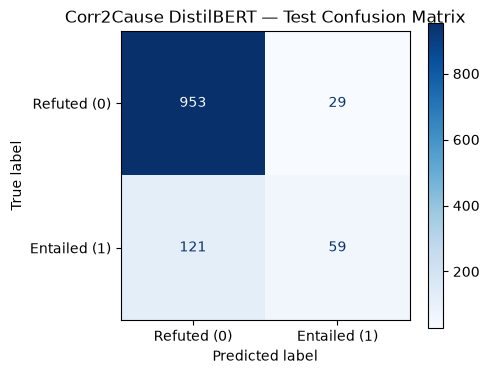

TEST METRICS BY NUMBER OF VARIABLES (num_variables)
  Group num_variables=2 (n=  6): Accuracy=0.8333 | Precision=0.5000 | Recall=0.4167 | Macro-F1=0.4545
  Group num_variables=3 (n= 48): Accuracy=0.8333 | Precision=0.6364 | Recall=0.9111 | Macro-F1=0.6655
  Group num_variables=4 (n= 72): Accuracy=0.9306 | Precision=0.5000 | Recall=0.4653 | Macro-F1=0.4820
  Group num_variables=5 (n=514): Accuracy=0.9261 | Precision=0.8423 | Recall=0.7434 | Macro-F1=0.7817
  Group num_variables=6 (n=522): Accuracy=0.8123 | Precision=0.8270 | Recall=0.6063 | Macro-F1=0.6227


In [7]:
# Section 7: Held-Out Test Split Evaluation
# The best checkpoint was restored by load_best_model_at_end=True
print('=' * 80)
print('HELD-OUT TEST SPLIT EVALUATION (1,162 instances)')
print('=' * 80)

# Single test inference pass using the restored best checkpoint
test_results = trainer.predict(test_tokenized)
test_logits = test_results.predictions
test_labels = test_results.label_ids
test_preds = np.argmax(test_logits, axis=-1)

# Softmax probabilities for binary classification
exp_logits = np.exp(test_logits - np.max(test_logits, axis=-1, keepdims=True))
test_probs = exp_logits / np.sum(exp_logits, axis=-1, keepdims=True)
prob_entailed = test_probs[:, 1]  # Model's softmax probability for class 1 (entailed)

# Overall classification metrics via dl_utils
overall_test_metrics = dl_utils.compute_classification_metrics(
    (test_logits, test_labels), average='macro'
)

print(f'\nOverall Test Performance:')
print(f'  Accuracy:        {overall_test_metrics["accuracy"]:.4f}')
print(f'  Macro Precision: {overall_test_metrics["precision"]:.4f}')
print(f'  Macro Recall:    {overall_test_metrics["recall"]:.4f}')
print(f'  Macro-F1:        {overall_test_metrics["f1"]:.4f}')

# Classification report
target_names = ['Refuted (0)', 'Entailed (1)']
print(f'\n--- Detailed Classification Report ---')
print(classification_report(test_labels, test_preds, target_names=target_names, digits=4))

# Confusion matrix
cm = confusion_matrix(test_labels, test_preds)
print(f'Confusion Matrix:\n{cm}')

# Plot Confusion Matrix
fig, ax = plt.subplots(figsize=(5, 4))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names)
disp.plot(ax=ax, cmap='Blues', values_format='d')
ax.set_title('Corr2Cause DistilBERT — Test Confusion Matrix')
plt.tight_layout()
plt.show()

# Evaluation Disaggregated by num_variables Groups (2, 3, 4)
print('\n' + '=' * 80)
print('TEST METRICS BY NUMBER OF VARIABLES (num_variables)')
print('=' * 80)
test_num_vars = test_df['num_variables'].values

variable_group_metrics = {}
for nv in [2, 3, 4]:
    mask = (test_num_vars == nv)
    count = int(mask.sum())
    if count == 0:
        print(f'  Group num_variables={nv}: 0 test examples (no instances)')
        variable_group_metrics[str(nv)] = {
            'num_variables': nv,
            'n_examples': 0,
            'accuracy': None,
            'precision': None,
            'recall': None,
            'f1': None,
            'note': 'No examples in test set'
        }
    else:
        sub_logits = test_logits[mask]
        sub_labels = test_labels[mask]
        sub_metrics = dl_utils.compute_classification_metrics(
            (sub_logits, sub_labels), average='macro'
        )
        print(f'  Group num_variables={nv} (n={count:>3}): ' 
              f'Accuracy={sub_metrics["accuracy"]:.4f} | ' 
              f'Precision={sub_metrics["precision"]:.4f} | ' 
              f'Recall={sub_metrics["recall"]:.4f} | ' 
              f'Macro-F1={sub_metrics["f1"]:.4f}')
        variable_group_metrics[str(nv)] = {
            'num_variables': nv,
            'n_examples': count,
            'accuracy': sub_metrics['accuracy'],
            'precision': sub_metrics['precision'],
            'recall': sub_metrics['recall'],
            'f1': sub_metrics['f1'],
        }

# Also report higher variable counts if present
remaining_vars = sorted(set(test_num_vars) - {2, 3, 4})
for nv in remaining_vars:
    mask = (test_num_vars == nv)
    count = int(mask.sum())
    sub_logits = test_logits[mask]
    sub_labels = test_labels[mask]
    sub_metrics = dl_utils.compute_classification_metrics(
        (sub_logits, sub_labels), average='macro'
    )
    print(f'  Group num_variables={nv} (n={count:>3}): ' 
          f'Accuracy={sub_metrics["accuracy"]:.4f} | ' 
          f'Precision={sub_metrics["precision"]:.4f} | ' 
          f'Recall={sub_metrics["recall"]:.4f} | ' 
          f'Macro-F1={sub_metrics["f1"]:.4f}')
    variable_group_metrics[str(nv)] = {
        'num_variables': nv,
        'n_examples': count,
        'accuracy': sub_metrics['accuracy'],
        'precision': sub_metrics['precision'],
        'recall': sub_metrics['recall'],
        'f1': sub_metrics['f1'],
    }

In [8]:
# Section 8: Export Predictions & Evaluation Metrics
EXPORT_DIR = ROOT_DIR / 'data' / 'processed'
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Export test predictions DataFrame
predictions_export = pd.DataFrame({
    'index': range(len(test_df)),
    'true_label': test_labels,
    'pred_label': test_preds,
    'prob_entailed': prob_entailed,
    'num_variables': test_df['num_variables'].values,
})

pred_path = EXPORT_DIR / 'dl_corr2cause_test_predictions.csv'
predictions_export.to_csv(pred_path, index=False)
print(f'Predictions exported to: {pred_path}')

# If running in Kaggle, also copy to /kaggle/working for immediate export
if Path('/kaggle/working').exists():
    kaggle_pred_path = Path('/kaggle/working/dl_corr2cause_test_predictions.csv')
    predictions_export.to_csv(kaggle_pred_path, index=False)
    print(f'Kaggle export mirror: {kaggle_pred_path}')

# Verification of exported predictions
print('\n--- Export Verification ---')
pred_verify = pd.read_csv(pred_path)
assert len(pred_verify) == 1162, f'Expected 1162 rows, got {len(pred_verify)}'
print(f'  ✓ Exact row count verified: {len(pred_verify)} rows')

req_pred_cols = ['index', 'true_label', 'pred_label', 'prob_entailed', 'num_variables']
assert list(pred_verify.columns) == req_pred_cols, f'Schema mismatch: {list(pred_verify.columns)}'
print(f'  ✓ Required columns verified: {req_pred_cols}')

assert pred_verify['pred_label'].isna().sum() == 0, 'Found NaN in pred_label'
assert pred_verify['prob_entailed'].isna().sum() == 0, 'Found NaN in prob_entailed'
assert pred_verify['prob_entailed'].between(0.0, 1.0).all(), 'Probabilities out of [0, 1] range'
print('  ✓ Zero missing predictions and all probabilities strictly within [0.0, 1.0]')

print('\nPredictions Preview (First 5 Rows):')
print(pred_verify.head())

# 2. Export compact metrics JSON
metrics_export = {
    'task': 'Corr2Cause DistilBERT Fine-Tuning',
    'model': MODEL_CHECKPOINT,
    'best_checkpoint': best_ckpt,
    'best_val_macro_f1': float(best_metric),
    'epoch_metrics': epoch_metrics,
    'test_overall': {
        'n_examples': int(len(test_labels)),
        'accuracy': overall_test_metrics['accuracy'],
        'precision': overall_test_metrics['precision'],
        'recall': overall_test_metrics['recall'],
        'f1': overall_test_metrics['f1'],
    },
    'test_by_num_variables': variable_group_metrics,
    'confusion_matrix': cm.tolist(),
    'hyperparameters': {
        'num_train_epochs': NUM_EPOCHS,
        'batch_size': BATCH_SIZE,
        'gradient_accumulation_steps': GRAD_ACCUM_STEPS,
        'learning_rate': LEARNING_RATE,
        'weight_decay': WEIGHT_DECAY,
        'max_length': MAX_LENGTH,
        'fp16': FP16_ENABLED,
        'seed': SEED,
    }
}

metrics_path = EXPORT_DIR / 'dl_corr2cause_test_metrics.json'
with open(metrics_path, 'w') as f:
    json.dump(metrics_export, f, indent=2, default=lambda x: x.item() if hasattr(x, "item") else str(x))
print(f'\nMetrics JSON exported to: {metrics_path}')

if Path('/kaggle/working').exists():
    kaggle_metrics_path = Path('/kaggle/working/dl_corr2cause_test_metrics.json')
    with open(kaggle_metrics_path, 'w') as f:
        json.dump(metrics_export, f, indent=2, default=lambda x: x.item() if hasattr(x, "item") else str(x))
    print(f'Kaggle metrics mirror: {kaggle_metrics_path}')

print(f'\n--- Exported Metrics Summary ---')
print(json.dumps(metrics_export, indent=2, default=lambda x: x.item() if hasattr(x, "item") else str(x)))

Predictions exported to: /kaggle/working/causal-nlp-reasoning/data/processed/dl_corr2cause_test_predictions.csv
Kaggle export mirror: /kaggle/working/dl_corr2cause_test_predictions.csv

--- Export Verification ---
  ✓ Exact row count verified: 1162 rows
  ✓ Required columns verified: ['index', 'true_label', 'pred_label', 'prob_entailed', 'num_variables']
  ✓ Zero missing predictions and all probabilities strictly within [0.0, 1.0]

Predictions Preview (First 5 Rows):
   index  true_label  pred_label  prob_entailed  num_variables
0      0           0           1       0.998116              2
1      1           0           0       0.000122              2
2      2           0           0       0.000111              2
3      3           0           0       0.000114              2
4      4           0           0       0.000105              2

Metrics JSON exported to: /kaggle/working/causal-nlp-reasoning/data/processed/dl_corr2cause_test_metrics.json
Kaggle metrics mirror: /kaggle/working/

In [9]:
# Section 9: Save Best Model & Tokenizer
BEST_MODEL_DIR = ROOT_DIR / 'DL' / 'models' / 'corr2cause_distilbert_best'
BEST_MODEL_DIR.mkdir(parents=True, exist_ok=True)

print(f'Saving best model weights and tokenizer to: {BEST_MODEL_DIR}')
trainer.save_model(str(BEST_MODEL_DIR))
tokenizer.save_pretrained(str(BEST_MODEL_DIR))

print('\nSaved Model Artifacts:')
for f in sorted(BEST_MODEL_DIR.iterdir()):
    size_kb = f.stat().st_size / 1024
    print(f'  ✓ {f.name:<30} ({size_kb:>8.1f} KB)')

Saving best model weights and tokenizer to: /kaggle/working/causal-nlp-reasoning/DL/models/corr2cause_distilbert_best

Saved Model Artifacts:
  ✓ config.json                    (     0.6 KB)
  ✓ model.safetensors              (261555.2 KB)
  ✓ tokenizer.json                 (   694.8 KB)
  ✓ tokenizer_config.json          (     0.4 KB)


In [10]:
# Section 10: Task Completion Summary
print('=' * 80)
print('TASK 2 COMPLETION SUMMARY: DistilBERT Fine-Tuning on Corr2Cause')
print('=' * 80)
print(f'Hardware Device:            {device}')
print(f'FP16 Acceleration:          {FP16_ENABLED}')
print(f'Training Duration:          {train_result.metrics["train_runtime"]:.1f} s ({train_result.metrics["train_runtime"]/60:.2f} min)')
print(f'Completed Epochs:           {NUM_EPOCHS}')
print(f'Selected Best Checkpoint:   {best_ckpt}')
print(f'Best Validation Macro-F1:   {best_metric:.4f}')
print(f'Final Test Accuracy:        {overall_test_metrics["accuracy"]:.4f}')
print(f'Final Test Macro-F1:        {overall_test_metrics["f1"]:.4f}')
print(f'Predictions Export Path:    {pred_path}')
print(f'Metrics Export Path:        {metrics_path}')
print(f'Best Model Save Path:       {BEST_MODEL_DIR}')
print('=' * 80)

TASK 2 COMPLETION SUMMARY: DistilBERT Fine-Tuning on Corr2Cause
Hardware Device:            cuda
FP16 Acceleration:          True
Training Duration:          8217.4 s (136.96 min)
Completed Epochs:           3
Selected Best Checkpoint:   /kaggle/working/causal-nlp-reasoning/DL/checkpoints/corr2cause_distilbert/checkpoint-19290
Best Validation Macro-F1:   0.6848
Final Test Accuracy:        0.8709
Final Test Macro-F1:        0.6837
Predictions Export Path:    /kaggle/working/causal-nlp-reasoning/data/processed/dl_corr2cause_test_predictions.csv
Metrics Export Path:        /kaggle/working/causal-nlp-reasoning/data/processed/dl_corr2cause_test_metrics.json
Best Model Save Path:       /kaggle/working/causal-nlp-reasoning/DL/models/corr2cause_distilbert_best


## 5. Expected Outputs & Evaluation Criteria

- Best model checkpoint (saved locally in temporary checkpoint dir).
- `data/processed/dl_corr2cause_test_predictions.csv`: Model predictions for all 1,162 test instances.
- **Evaluation Criteria**: Test Accuracy, Macro-F1, Precision, and Recall reported overall and disaggregated across variable counts (2, 3, 4 variables).